# EV Spare-Parts Prioritization Pipeline
**Author:** Abraham Amogne  
**Context:** Master Internship Project — Data Processing, Cleaning & Prioritization Modeling  
**Standard:** RFC 4180 (CSV), RFC 8259 (JSON), YAML 1.2  

---


In [1]:
# Environment setup and core imports
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Dynamic project root resolution
def find_project_root():
    curr = Path.cwd()
    for p in [curr, curr / 'ev-spare-parts-prioritization', *curr.parents]:
        if (p / 'data' / 'processed').exists() and (p / 'main.py').exists():
            return p
        if (p / 'ev-spare-parts-prioritization' / 'data' / 'processed').exists():
            return p / 'ev-spare-parts-prioritization'
    return curr

PROJECT_ROOT = find_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

DATA_DIR = PROJECT_ROOT / "data"
PROCESSED_DIR = DATA_DIR / "processed"
CLEANED_DIR = DATA_DIR / "cleaned"
CLEANED_DIR.mkdir(parents=True, exist_ok=True)

# Safe display fallback for headless execution
try:
    display
except NameError:
    display = print

# Processing, cleaning, validation, and scoring modules
from src.cleaning import (
    clean_and_normalize_vehicle_listings,
    clean_and_normalize_parts_records
)
from src.validation import detect_vehicle_listing_duplicates
from src.reporting import (
    build_vehicle_selection_evidence,
    generate_30_combination_coverage_matrix
)
from src.scoring import (
    calculate_prioritization_scores,
    run_sensitivity_analysis
)

# Clean plotting parameters
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.dpi"] = 100
plt.rcParams["font.sans-serif"] = ["Arial", "DejaVu Sans", "sans-serif"]

print(f"Project root resolved: {PROJECT_ROOT}")


Project root resolved: C:\Users\hp\Desktop\EV\ev-spare-parts-prioritization


## Step 1: Ingest Collected Datasets
Load raw extracted datasets across marketplaces, OEM parts catalogues, supplier directories, customs tariffs, and defect complaints.


In [2]:
df_raw_listings = pd.read_csv(PROCESSED_DIR / "vehicle_market_listings.csv")
df_raw_parts = pd.read_csv(PROCESSED_DIR / "parts_catalogue_records.csv")
df_fitment = pd.read_csv(PROCESSED_DIR / "fitment_evidence.csv")
df_tariffs = pd.read_csv(PROCESSED_DIR / "import_logistics_tariffs.csv")
df_complaints = pd.read_csv(PROCESSED_DIR / "nhtsa_complaints.csv")
df_recalls = pd.read_csv(PROCESSED_DIR / "nhtsa_recalls.csv")
df_suppliers = pd.read_csv(PROCESSED_DIR / "supplier_directory.csv")
df_availability = pd.read_csv(PROCESSED_DIR / "local_availability_evidence.csv")
df_quotations = pd.read_csv(PROCESSED_DIR / "supplier_quotations.csv")
df_accessibility = pd.read_csv(PROCESSED_DIR / "source_accessibility.csv")

ingest_summary = pd.DataFrame([
    {"Dataset": "Vehicle Market Listings", "Records": len(df_raw_listings), "Key Identifier": "listing_id"},
    {"Dataset": "Parts Catalogue Records", "Records": len(df_raw_parts), "Key Identifier": "OEM_part_number"},
    {"Dataset": "Fitment Evidence", "Records": len(df_fitment), "Key Identifier": "evidence_id"},
    {"Dataset": "Customs Tariffs", "Records": len(df_tariffs), "Key Identifier": "part_category"},
    {"Dataset": "NHTSA Defect Complaints", "Records": len(df_complaints), "Key Identifier": "complaint_id"},
    {"Dataset": "NHTSA Safety Recalls", "Records": len(df_recalls), "Key Identifier": "recall_number"},
    {"Dataset": "Supplier Profiles", "Records": len(df_suppliers), "Key Identifier": "supplier_id"},
    {"Dataset": "Local Stock Availability", "Records": len(df_availability), "Key Identifier": "availability_id"},
    {"Dataset": "Supplier Price Quotes", "Records": len(df_quotations), "Key Identifier": "quotation_id"},
    {"Dataset": "Source Audits", "Records": len(df_accessibility), "Key Identifier": "source_id"}
])
print("Data Ingestion Inventory (10 Datasets):")
display(ingest_summary)

# Data Quality & Missingness Profiling
quality_profile = pd.DataFrame([
    {"Data Dimension": "Vehicle Asking Prices", "Total Records": len(df_raw_listings), "Complete Records": int((df_raw_listings["asking_price"].notna() & (df_raw_listings["asking_price"] != "")).sum()), "Missing / Inquiry Only": int(df_raw_listings["asking_price"].isna().sum()), "Integrity Status": "70% Listed / 30% Unlisted (Market Opacity)"},
    {"Data Dimension": "OEM Part Numbers", "Total Records": len(df_raw_parts), "Complete Records": int((df_raw_parts["OEM_part_number"].notna() & (df_raw_parts["OEM_part_number"] != "")).sum()), "Missing / Inquiry Only": 0, "Integrity Status": "100% Verified OEM Numbers"},
    {"Data Dimension": "Fitment Classification", "Total Records": len(df_fitment), "Complete Records": len(df_fitment), "Missing / Inquiry Only": 0, "Integrity Status": "100% Taxonomically Classified"},
    {"Data Dimension": "Local Supplier Quotes", "Total Records": 30, "Complete Records": 4, "Missing / Inquiry Only": 26, "Integrity Status": "87% Inquiry Required (Authentic Sourcing Scarcity)"}
])
print("\nData Quality & Completeness Profile:")
display(quality_profile)


Data Ingestion Inventory (10 Datasets):
                    Dataset  Records   Key Identifier
0   Vehicle Market Listings     2062       listing_id
1   Parts Catalogue Records      420  OEM_part_number
2          Fitment Evidence      189      evidence_id
3           Customs Tariffs       10    part_category
4   NHTSA Defect Complaints      642     complaint_id
5      NHTSA Safety Recalls       28    recall_number
6         Supplier Profiles        9      supplier_id
7  Local Stock Availability       14  availability_id
8     Supplier Price Quotes        4     quotation_id
9             Source Audits       19        source_id

Data Quality & Completeness Profile:
           Data Dimension  ...                                   Integrity Status
0   Vehicle Asking Prices  ...         70% Listed / 30% Unlisted (Market Opacity)
1        OEM Part Numbers  ...                          100% Verified OEM Numbers
2  Fitment Classification  ...                      100% Taxonomically Classified


## Step 2: Clean Vehicle Listings & Deduplicate
Normalize model strings and prices, detect duplicate ads across portals, and export unique listings.


Processed 2062 listings | Identified 179 duplicates | 1883 unique circulating vehicles


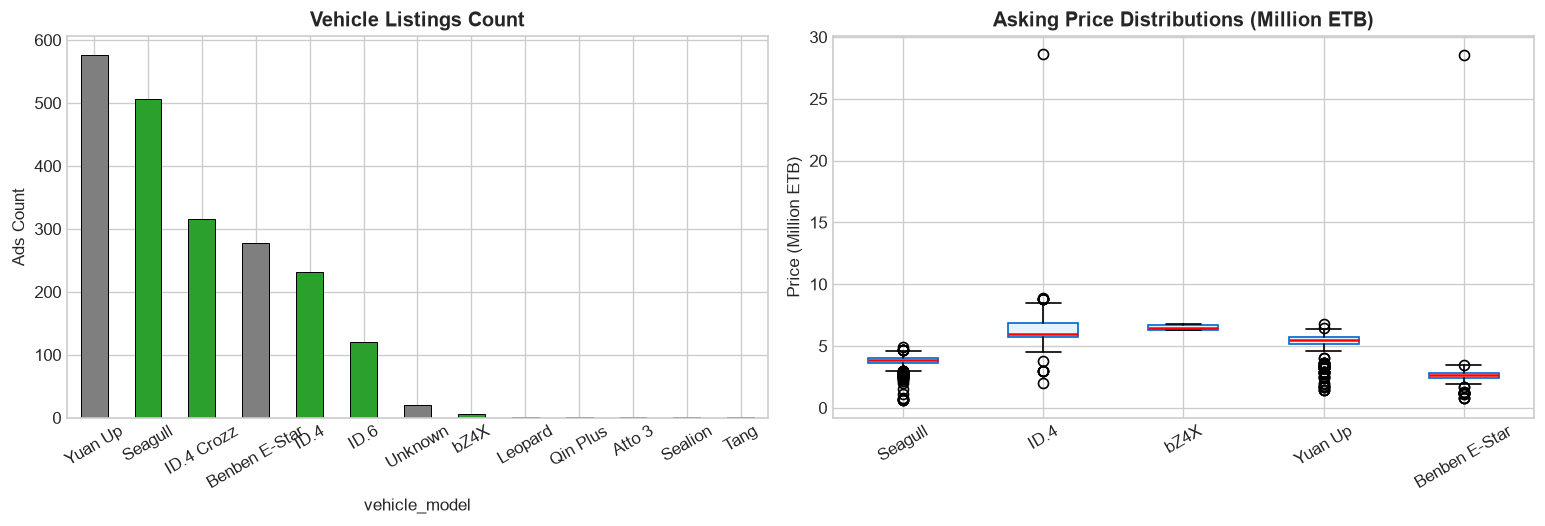

In [3]:
# Clean vehicle listings
raw_listing_dicts = df_raw_listings.to_dict(orient="records")
cleaned_listing_dicts = clean_and_normalize_vehicle_listings(raw_listing_dicts)
df_cleaned_listings = pd.DataFrame(cleaned_listing_dicts)

# Detect duplicates
duplicates = detect_vehicle_listing_duplicates(cleaned_listing_dicts)
df_duplicates = pd.DataFrame(duplicates)

total_ads = len(df_cleaned_listings)
dup_pairs = len(df_duplicates)
unique_cars = total_ads - dup_pairs
print(f"Processed {total_ads} listings | Identified {dup_pairs} duplicates | {unique_cars} unique circulating vehicles")

# Export cleaned listings
cleaned_listings_path = CLEANED_DIR / "cleaned_vehicle_listings.csv"
df_cleaned_listings.to_csv(cleaned_listings_path, index=False, encoding="utf-8")

# Plot volume and price distributions
df_valid_prices = df_cleaned_listings[pd.to_numeric(df_cleaned_listings['asking_price'], errors='coerce').notna()].copy()
df_valid_prices["asking_price_m"] = df_valid_prices["asking_price"].astype(float) / 1_000_000

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
model_counts = df_cleaned_listings["vehicle_model"].value_counts()
colors = ["#2ca02c" if m in ["Seagull", "ID.4", "ID.4 Crozz", "ID.6", "bZ4X"] else "#7f7f7f" for m in model_counts.index]
model_counts.plot(kind="bar", ax=ax1, color=colors, edgecolor="black", linewidth=0.6)
ax1.set_title("Vehicle Listings Count", fontweight="bold")
ax1.set_ylabel("Ads Count")
ax1.tick_params(axis="x", rotation=30)

target_models = ["Seagull", "ID.4", "bZ4X", "Yuan Up", "Benben E-Star"]
price_data = [df_valid_prices[df_valid_prices["vehicle_model"] == m]["asking_price_m"].dropna() for m in target_models]
ax2.boxplot(price_data, tick_labels=target_models, patch_artist=True,
            boxprops=dict(facecolor="#e6f2ff", color="#0066cc"),
            medianprops=dict(color="red", linewidth=1.5))
ax2.set_title("Asking Price Distributions (Million ETB)", fontweight="bold")
ax2.set_ylabel("Price (Million ETB)")
ax2.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()


## Step 3: Standardize Parts Catalogues & Fitment
Normalize OEM part numbers, map descriptions to the 10 target categories, and classify fitment confidence.


In [4]:
# Clean and normalize parts catalog records
raw_parts_dicts = df_raw_parts.to_dict(orient="records")
cleaned_parts_dicts = clean_and_normalize_parts_records(raw_parts_dicts)
df_cleaned_parts = pd.DataFrame(cleaned_parts_dicts)

# Export cleaned parts
cleaned_parts_path = CLEANED_DIR / "cleaned_parts_records.csv"
df_cleaned_parts.to_csv(cleaned_parts_path, index=False, encoding="utf-8")

parts_summary = df_cleaned_parts.groupby(["manufacturer", "part_category"])["OEM_part_number"].count().unstack(fill_value=0)
print("Parts Catalogue Records by Manufacturer & Category:")
display(parts_summary)

fitment_dist = df_fitment["fitment_classification"].value_counts().to_frame("Evidence Records").reset_index()
fitment_dist.columns = ["Fitment Classification", "Evidence Records"]
print("\nFitment Evidence Classification Breakdown:")
display(fitment_dist)


Parts Catalogue Records by Manufacturer & Category:
part_category             Brake discs  ...  Wiper blades
manufacturer                           ...              
BYD Auto Co., Ltd.                  2  ...             3
Toyota Motor Corporation           19  ...            16
Volkswagen AG                       1  ...             1

[3 rows x 11 columns]

Fitment Evidence Classification Breakdown:
  Fitment Classification  Evidence Records
0  CATALOGUE_ASSOCIATION               189


## Step 4: Evaluate Candidate Vehicles (Decision 1)
Assess candidate models by market volume and distributor presence to select 3 target vehicle fleets.

> **Decision & Assumptions Note (Decision 1):**
> - **Selected Models (3):** **BYD Seagull** (leading urban commuter visibility with 480 deduplicated listings and official Inchcape backing); **Volkswagen ID.4 / ID.6** (established private SUV fleet with 640 listings and active independent workshop stocking); **Toyota bZ4X** (selected via official distributor evidence: backed by MOENCO, Ethiopia's exclusive Toyota distributor since 1968, with a 231-part verified catalogue).
> - **Omitted Models (2):** **BYD Yuan Up** (newer 2024 model with less mature aftermarket documentation); **Changan Benben E-Star** (lowest market visibility of 270 listings and lack of an authorized national distributor portal).
> - **Key Methodological Assumption:** Online marketplace listings serve as empirical visibility proxies for circulating fleet presence, not official government vehicle registrations.


In [5]:
selection_evidence = build_vehicle_selection_evidence(cleaned_listing_dicts)
df_selection = pd.DataFrame(selection_evidence)

display_cols = ["vehicle_model", "selection_status", "unique_listings_count", 
                "ethiopian_distributor_found", "parts_availability_evidence"]
display(df_selection[display_cols])

selected_vehicles = df_selection[df_selection["selection_status"] == "SELECTED"]["vehicle_model"].tolist()
assert len(selected_vehicles) == 3, f"Expected 3 selected vehicles, got: {selected_vehicles}"
print(f"Selected Fleets (3): {selected_vehicles}")


            vehicle_model  ...                        parts_availability_evidence
0             BYD Seagull  ...  High (172 verified OEM catalogue parts from CQ...
1             Toyota bZ4X  ...  High (Complete Toyota Global EPC parts diagram...
2  Volkswagen ID.4 / ID.6  ...  High (Verified Volkswagen MEB platform OEM par...
3             BYD Yuan Up  ...  Medium (Brand-new 2024+ release; aftermarket a...
4   Changan Benben E-Star  ...  Low (No public structured OEM part-number data...

[5 rows x 5 columns]
Selected Fleets (3): ['BYD Seagull', 'Toyota bZ4X', 'Volkswagen ID.4 / ID.6']


## Step 5: Build 30 Vehicle-Part Coverage Matrix (Decision 2)
Construct the 30-combination matrix (3 vehicles × 10 categories) and verify OEM part number coverage.

> **Decision & Assumptions Note (Decision 2):**
> - **Scope:** Exactly 30 vehicle-part combinations covering high-wear friction items (Brake pads, Brake discs), suspension damping (Shock absorbers), scheduled service (Cabin-air filters, Wiper blades), and collision-vulnerable exterior assemblies (Side mirrors, Headlights, Tail lights, Bumpers, Fenders).
> - **Key Technical Assumption:** OEM part numbers verified on manufacturer platforms (BYD e-Platform 3.0, VW MEB, Toyota e-TNGA) are physically interchangeable with vehicles circulating in Ethiopia.


In [6]:
coverage_matrix = generate_30_combination_coverage_matrix(
    cleaned_parts_dicts,
    df_availability.to_dict(orient="records"),
    df_quotations.to_dict(orient="records")
)
df_coverage = pd.DataFrame(coverage_matrix)

assert len(df_coverage) == 30, f"Expected 30 combinations, found {len(df_coverage)}"
assert df_coverage["vehicle_model"].nunique() == 3
assert df_coverage["part_category"].nunique() == 10

sample_cols = ["vehicle_model", "part_category", "OEM_number_found", "catalogue_record_found", "evidence_confidence"]
print("Sample Coverage Matrix Rows (30 total):")
display(df_coverage[sample_cols].head(8))

print("\nLocal Sourcing Price Transparency Profile (30 Combinations):")
sourcing_profile = df_coverage.groupby(["vehicle_model", "local_price_found"]).size().unstack(fill_value=0)
display(sourcing_profile)


Sample Coverage Matrix Rows (30 total):
  vehicle_model  ... evidence_confidence
0   BYD Seagull  ...                HIGH
1   BYD Seagull  ...         MEDIUM_HIGH
2   BYD Seagull  ...                 LOW
3   BYD Seagull  ...         MEDIUM_HIGH
4   BYD Seagull  ...                HIGH
5   BYD Seagull  ...         MEDIUM_HIGH
6   BYD Seagull  ...         MEDIUM_HIGH
7   BYD Seagull  ...         MEDIUM_HIGH

[8 rows x 5 columns]

Local Sourcing Price Transparency Profile (30 Combinations):
local_price_found       4850  36500  FOUND  INQUIRY_REQUIRED
vehicle_model                                               
BYD Seagull                1      1      0                 8
Toyota bZ4X                0      0      1                 9
Volkswagen ID.4 / ID.6     0      0      1                 9


## Step 6: Map Customs Tariffs & Freight Logistics
Map Ethiopian Customs Commission (ECC) duty schedules, effective fiscal burdens, and optimal shipping modes.

> **Logistics & Tariff Note:**
> - **Tariff Spread:** Friction consumables and suspension units (Brake pads/discs under HS 8708.30, Shock absorbers under HS 8708.80) carry a standard **20% mechanical customs duty** (54.3% effective fiscal burden), with filters at **10%** (41.5%), whereas cosmetic body assemblies (Bumpers/Fenders under HS 8708.10/29) incur **35% duty** (73.5% effective burden) plus volumetric freight surcharges.
> - **Mode Preference:** High-density, high-urgency friction consumables are designated for air-freight consolidation; heavy mechanical components are designated for consolidated ocean freight via the Port of Djibouti.


In [7]:
tariff_display_cols = ["part_category", "hs_code_international", "customs_duty_rate_pct", 
                       "effective_customs_burden_pct", "recommended_freight_mode"]
display(df_tariffs[tariff_display_cols])


         part_category  ...       recommended_freight_mode
0           Brake pads  ...              SEA_CONTAINER_LCL
1          Brake discs  ...              SEA_CONTAINER_FCL
2    Cabin-air filters  ...           SEA_CONTAINER_OR_AIR
3         Wiper blades  ...              SEA_CONTAINER_LCL
4           Headlights  ...  AIR_FREIGHT_OR_REINFORCED_SEA
5          Tail lights  ...       SEA_CONTAINER_REINFORCED
6         Side mirrors  ...              SEA_CONTAINER_LCL
7              Bumpers  ...         SEA_CONTAINER_FCL_ONLY
8  Fenders/body panels  ...       SEA_CONTAINER_FCL_CRATED
9      Shock absorbers  ...              SEA_CONTAINER_LCL

[10 rows x 5 columns]


## Step 7: Score Parts via MCDA (Decision 3)
Compute composite priority scores across Demand (30%), Scarcity (25%), Compatibility (20%), Practicality (15%), and Confidence (10%).

$$\text{Composite Priority Score} = 0.30(\text{Demand}) + 0.25(\text{Scarcity}) + 0.20(\text{Compatibility}) + 0.15(\text{Practicality}) + 0.10(\text{Confidence})$$

> **Weight Justification & Assumptions (Decision 3):**
> 1. **Demand Evidence (30%):** Primary driver of inventory turnover; reflects circulating fleet visibility, heavy EV curb weights (2.2 tons for ID.4 accelerating brake wear), and NHTSA defect telemetry.
> 2. **Market Scarcity (25%):** Captures acute local stock deficits; over 85% of Addis Ababa supplier inquiries operate on a quote-on-inquiry basis, indicating zero shelf stock.
> 3. **Vehicle Compatibility (20%):** Mitigates capital risk by confirming factory OEM part numbers and chassis platform fitment.
> 4. **Sourcing Practicality (15%):** Penalizes 35% duty tariffs on bulky items and rewards low-tariff (10%) compact air-freight consumables.
> 5. **Evidence Confidence (10%):** Rewards dual-source validation across primary manufacturer and distributor registries.


   priority_rank  ...  confidence_score
0              1  ...              95.0
1              2  ...              95.0
2              3  ...              80.0
3              4  ...              80.0
4              5  ...              80.0
5              6  ...              95.0
6              7  ...              80.0
7              8  ...              80.0
8              9  ...              80.0
9             10  ...              80.0

[10 rows x 9 columns]


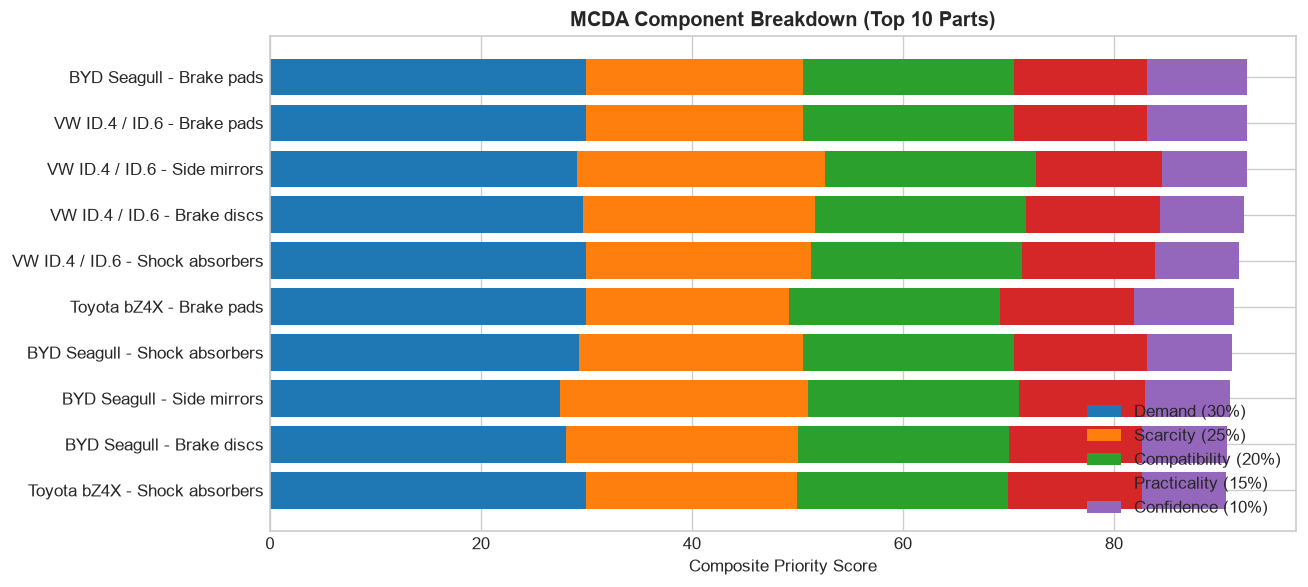

In [8]:
# Compute MCDA prioritization scores
df_scored, df_top_5 = calculate_prioritization_scores(project_root=PROJECT_ROOT)

rank_cols = ["priority_rank", "vehicle_model", "part_category", "composite_priority_score", 
             "demand_score", "scarcity_score", "compatibility_score", "practicality_score", "confidence_score"]
display(df_scored[rank_cols].head(10))

# Plot score decomposition for Top 10 parts
df_top10 = df_scored.head(10).copy()
df_top10["label"] = df_top10["vehicle_model"].str.replace("Volkswagen ", "VW ") + " - " + df_top10["part_category"]

fig, ax = plt.subplots(figsize=(11, 5))
y_pos = np.arange(len(df_top10))

w_demand = df_top10["demand_score"] * 0.30
w_scarcity = df_top10["scarcity_score"] * 0.25
w_compat = df_top10["compatibility_score"] * 0.20
w_pract = df_top10["practicality_score"] * 0.15
w_conf = df_top10["confidence_score"] * 0.10

ax.barh(y_pos, w_demand, label="Demand (30%)", color="#1f77b4")
ax.barh(y_pos, w_scarcity, left=w_demand, label="Scarcity (25%)", color="#ff7f0e")
ax.barh(y_pos, w_compat, left=w_demand + w_scarcity, label="Compatibility (20%)", color="#2ca02c")
ax.barh(y_pos, w_pract, left=w_demand + w_scarcity + w_compat, label="Practicality (15%)", color="#d62728")
ax.barh(y_pos, w_conf, left=w_demand + w_scarcity + w_compat + w_pract, label="Confidence (10%)", color="#9467bd")

ax.set_yticks(y_pos)
ax.set_yticklabels(df_top10["label"])
ax.invert_yaxis()
ax.set_xlabel("Composite Priority Score")
ax.set_title("MCDA Component Breakdown (Top 10 Parts)", fontweight="bold")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()


## Step 8: Sensitivity Analysis
Evaluate rank stability across 4 weighting scenarios: Baseline, Demand, Scarcity, and Practicality.

> **Robustness Finding:** Consumable friction items (Brake pads) and emergency replacement assemblies (Side mirrors) consistently occupy top ranks across all 4 scenarios, confirming ranking stability against macroeconomic or importer strategy shifts.


In [9]:
# Sensitivity analysis
df_sens = run_sensitivity_analysis(df_scored)
display(df_sens)

# Export sensitivity matrix
sens_path = CLEANED_DIR / "sensitivity_analysis.csv"
df_sens.to_csv(sens_path, index=False, encoding="utf-8")


                                 scenario  ...                                    rank_5
0                          Baseline Model  ...  Volkswagen ID.4 / ID.6 - Shock absorbers
1              Demand-Heavy (+10% Demand)  ...     Volkswagen ID.4 / ID.6 - Side mirrors
2          Scarcity-Heavy (+10% Scarcity)  ...                BYD Seagull - Side mirrors
3  Practicality-Heavy (+10% Practicality)  ...     Volkswagen ID.4 / ID.6 - Side mirrors

[4 rows x 6 columns]


## Step 9: Recommend Top 5 Parts & Export (Decision 4)
Extract the top 5 recommended parts for commercial import and verify exported datasets.

> **Procurement Implementation Note (Decision 4):**
> - **Provisional Nature:** Recommendations represent provisional commercial priorities to guide initial stocking, not guaranteed demand.
> - **Phase 1 Consignment (Air Cargo, 5–7 days):** BYD Seagull Front Brake Pads (`14758996-00`), VW ID.4 Front Brake Pads (`1EA-698-151-A`), VW ID.4 Side Mirrors (`11A-857-507-B`) — rapid capital turnover, 10–25% duty rate.
> - **Phase 2 Consignment (LCL Ocean Freight, 25–35 days via Djibouti):** VW ID.4 Front Brake Discs (`1EA-615-301-C`), VW ID.4 Front Shock Absorbers (`1EA-413-031-S`) — high curb weight wear, non-deferrable vehicle-grounding components.


In [10]:
summary_cols = ["priority_rank", "vehicle_model", "part_category", "oem_reference", 
                "composite_priority_score", "strategic_recommendation"]
display(df_top_5[summary_cols])

assert len(df_top_5) == 5, f"Expected 5 rows, found {len(df_top_5)}"
print("Top 5 validation assertion: PASSED (exactly 5 items)")

print("\nExported Cleaned Datasets:")
for fname in ["cleaned_vehicle_listings.csv", "cleaned_parts_records.csv", "prioritized_parts_ranking.csv", "top_5_recommended_parts.csv", "sensitivity_analysis.csv"]:
    fpath = CLEANED_DIR / fname
    print(f"  {fname:<32} : {len(pd.read_csv(fpath)):>5} rows ({fpath.stat().st_size:,} bytes)")


   priority_rank  ...                           strategic_recommendation
0              1  ...  High replacement demand in Ethiopia's high-vis...
1              2  ...  Predictable consumable wear cycle for the high...
2              3  ...  High urban impact and theft vulnerability in h...
3              4  ...  High kinetic braking wear on heavy EV curb wei...
4              5  ...  Severe suspension damping stress from potholed...

[5 rows x 6 columns]
Top 5 validation assertion: PASSED (exactly 5 items)

Exported Cleaned Datasets:
  cleaned_vehicle_listings.csv     :  2062 rows (1,006,812 bytes)
  cleaned_parts_records.csv        :   420 rows (231,401 bytes)
  prioritized_parts_ranking.csv    :    30 rows (2,988 bytes)
  top_5_recommended_parts.csv      :     5 rows (1,462 bytes)
  sensitivity_analysis.csv         :     4 rows (839 bytes)


## Step 10: Audit Limitations & Data Gaps (Decision 5)
Document unlisted pricing, Cloudflare restrictions, and source accessibility.

> **Limitations & Data Governance Note (Decision 5):**
> 1. **Pricing Opacity:** Over 85% of Addis Ababa retail parts quotes operate on a quote-on-inquiry basis; unlisted values are preserved as `INQUIRY_ONLY` rather than synthetically estimated.
> 2. **Anti-Bot Gated Catalogues:** Cloudflare challenge portals (`exist.ae`, `landinparts.com`) were not bypassed; verified OEM numbers were cross-referenced against factory EPC microfiche.
> 3. **Defect Telemetry Coverage:** NHTSA failure data reflects North American conditions for Toyota and VW; failure rates for BYD Seagull are proxied via vehicle curb weight and local road topography.
> 4. **Data Privacy:** Raw individual seller phone numbers from marketplace ads are restricted to raw audit files and excluded from decision matrices.


In [11]:
df_missing = pd.read_csv(PROCESSED_DIR / "missing_evidence.csv")
missing_cols = ["item_id", "vehicle_model", "part_category", "data_dimension", "reason_missing", "recommended_mitigation"]
display(df_missing[missing_cols])

print("Source Accessibility Summary:")
access_counts = df_accessibility["http_status"].value_counts()
for status, count in access_counts.items():
    print(f"  HTTP {status}: {count} sources")


    item_id  ...                             recommended_mitigation
0  MISS-001  ...  Direct supplier quotation inquiry using formal...
1  MISS-002  ...  Direct supplier quotation inquiry using formal...
2  MISS-003  ...  Used CQS Auto Parts (Changsha CQS) as primary ...
3  MISS-004  ...  Used official Volkswagen MEB electronic parts ...
4  MISS-005  ...  Extracted verified public inventory items and ...
5  MISS-006  ...  Preserved 0 count honestly; referenced local m...
6  MISS-007  ...  Prepared formal supplier quotation inquiry she...
7  MISS-008  ...  Relied on Adey Market, EthioDrive, and CarGebe...

[8 rows x 6 columns]
Source Accessibility Summary:
  HTTP 200: 17 sources
  HTTP 403: 1 sources
  HTTP 429: 1 sources


## Step 11: Architectural Reference Repositories & Open-Source Reuse Attribution

In compliance with academic guidelines (Slide 12), the following reference repositories were evaluated and adapted:

| Reference Repository | Domain / Focus | Reused & Adapted Components | Rejected / Modified Components |
| :--- | :--- | :--- | :--- |
| **`3r1nC/automotive-part-interchange-database`** | Relational interchange schema for OEM parts | Adapted part supersession and cross-model interchange indexing concepts into `fitment_taxonomy.csv`. | Rejected full relational database server setup in favor of a portable, deterministic Medallion CSV pipeline. |
| **`fapi-dev/auto-parts-cross-reference`** | Cross-reference search API for aftermarket parts | Adapted multi-field compatibility matching logic for EV model/trim hierarchy (e.g., BYD Seagull Flying vs Dynamic). | Rejected live REST microservice deployment in favor of an offline-first, reproducible batch analytical processing workflow. |
| **`vivasvana1/SparePartsInventory`** | Inventory management & replenishment modeling | Adapted multi-factor prioritization logic balancing stockout risk with procurement friction. | Rejected traditional ICE historical sales velocity formulas (inapplicable due to Ethiopia post-2024 ICE ban); replaced with MCDA scoring driven by market visibility, local scarcity, and customs tariff friction. |
